GoogLeNet + EfficientNet-B0

EXPERIMENT: GoogLeNet_EfficientNetB0 | DEVICE: cuda
Verified original image-label pairs: 2317
class_name
clean            615
pine_pollen      561
sand             457
plastic_bag      270
bird_dropping    252
shadow           162
Auditing exact and perceptual hashes...


SHA256:   0%|          | 0/2317 [00:00<?, ?it/s]

dHash:   0%|          | 0/2317 [00:00<?, ?it/s]

/tmp/ipykernel_50/2912295954.py:154: UserWarning: 10 possible cross-split near-duplicate matches shown (up to 10). Review before publication.
  warnings.warn(f'{len(near_pairs)} possible cross-split near-duplicate matches '


TRAINING images: 1632 | TESTING images: 685
TRAINING days: 5 | TESTING days: 3
Perceptual near-duplicate audit examples: 10
Internal holdout method: panel recording sessions (>=60 minute gap)
Training-only early-stopping subset: 1307 | temporary holdout: 325


/usr/local/lib/python3.13/dist-packages/torchvision/models/googlenet.py:341: UserWarning: auxiliary heads in the pretrained googlenet model are NOT pretrained, so make sure to train them
  warnings.warn(


... (74 outputs left out)

FINAL epoch 12 Fine-Tuning | TRAINING ACCURACY: 99.88%


Training:   0%|          | 0/204 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a1ffc7b87c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a1ffc7b87c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

FINAL epoch 13 Fine-Tuning | TRAINING ACCURACY: 99.82%

============== FINAL RESULTS ==============
GoogLeNet_EfficientNetB0
TRAINING ACCURACY: 99.94%
TESTING ACCURACY : 98.98%
TEST MACRO-F1    : 98.69%
GENERALIZATION GAP (train-test): 0.96 points
               precision    recall  f1-score   support

bird_dropping       1.00      1.00      1.00        77
        clean       1.00      1.00      1.00       181
  pine_pollen       0.98      1.00      0.99       176
  plastic_bag       0.96      0.96      0.96        45
         sand       0.99      0.96      0.97       138
       shadow       1.00      1.00      1.00        68

     accuracy                           0.99       685
    macro avg       0.99      0.99      0.99       685
 weighted avg       0.99      0.99      0.99       685



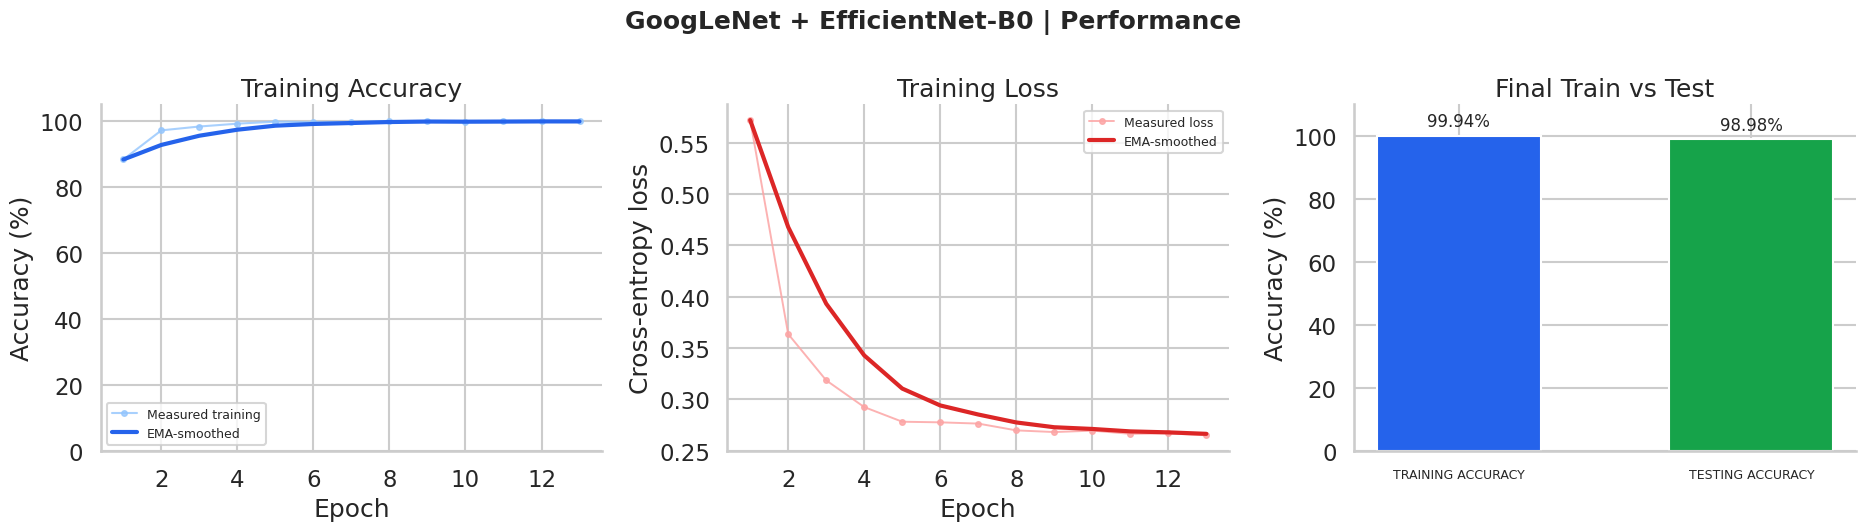

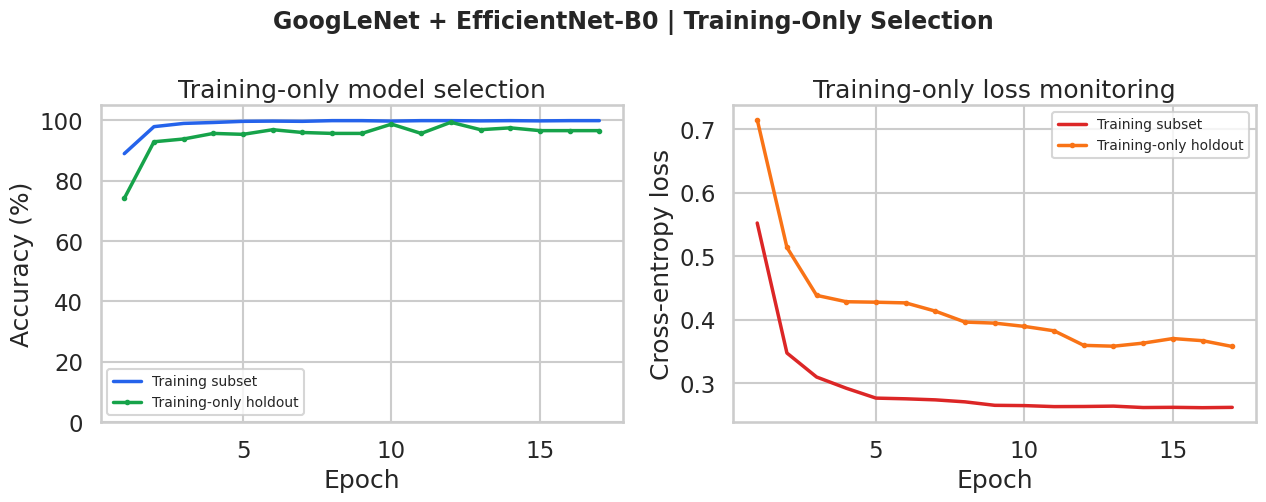

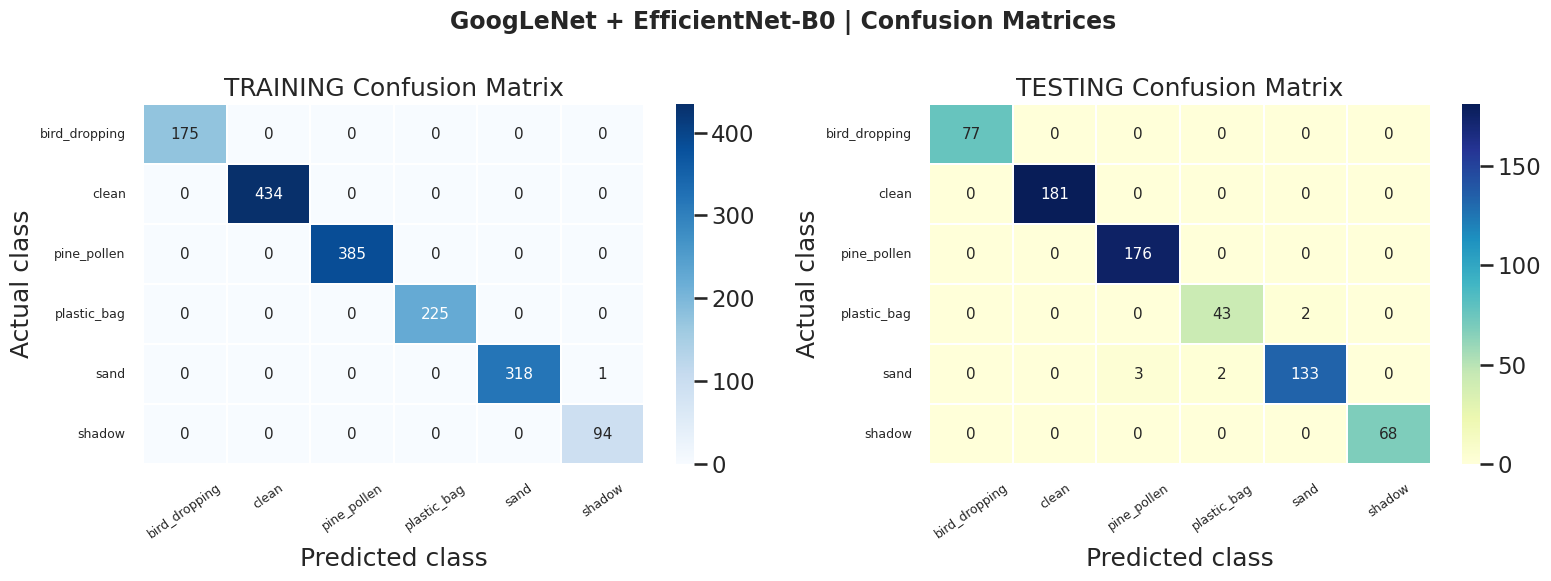

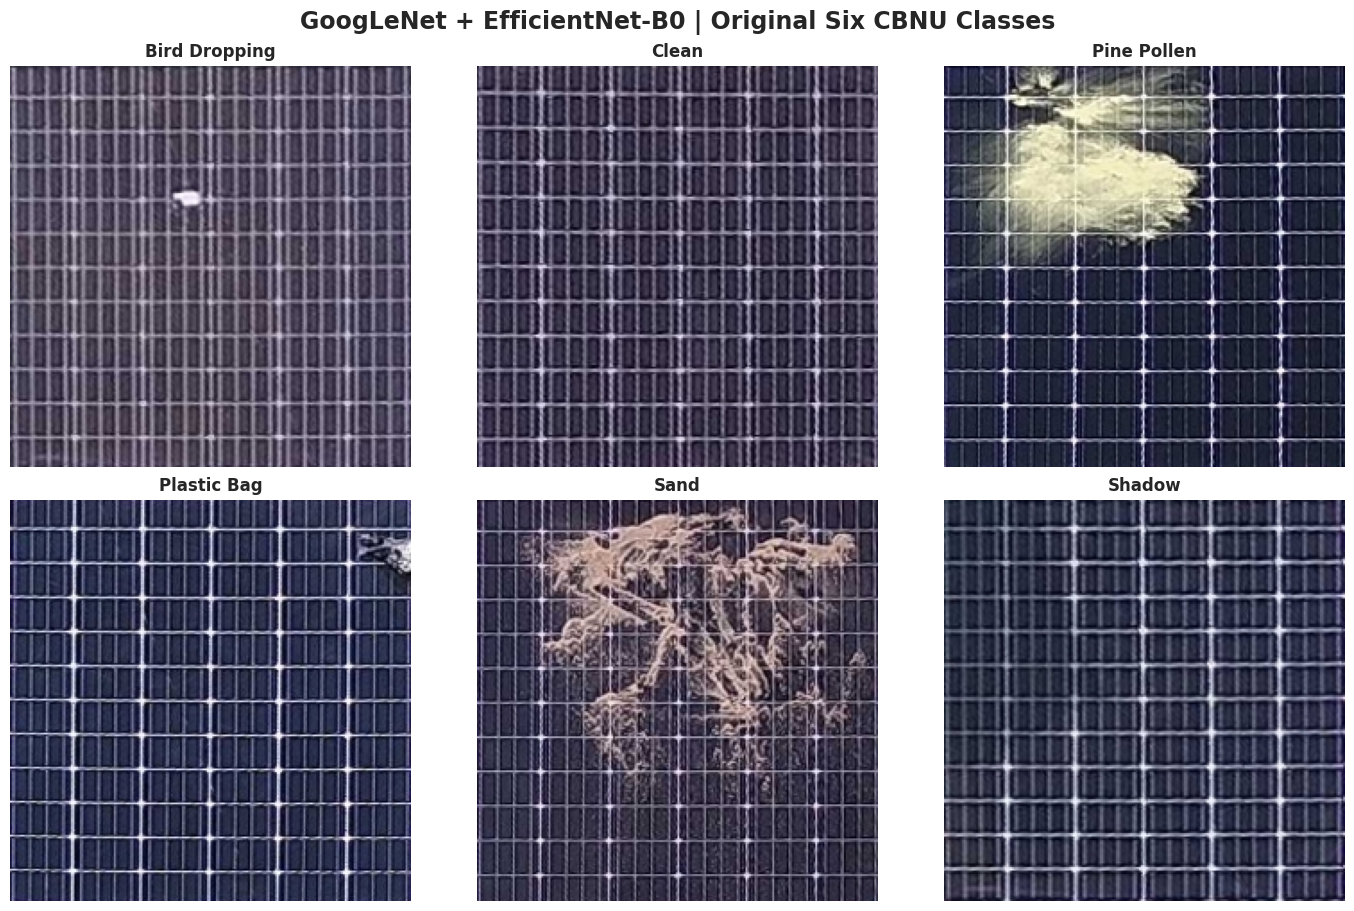

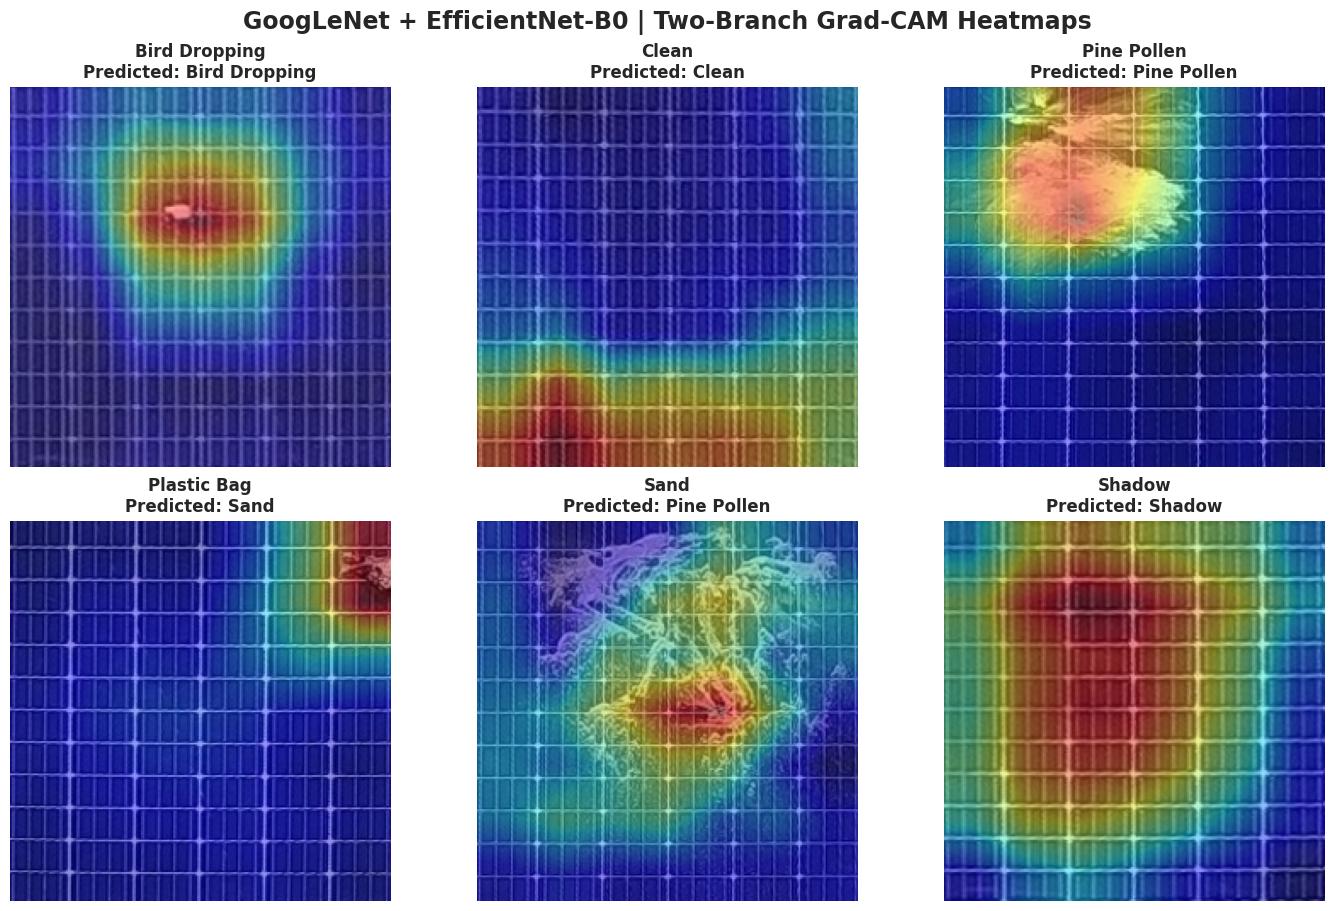


SAVED PNG FIGURES AND METRICS IN: /kaggle/working/hybrid_results/GoogLeNet_EfficientNetB0


/kaggle/working/hybrid_results/GoogLeNet_EfficientNetB0/google_eff_accuracy_graphs.png

/kaggle/working/hybrid_results/GoogLeNet_EfficientNetB0/google_eff_training_only_selection.png

/kaggle/working/hybrid_results/GoogLeNet_EfficientNetB0/google_eff_confusion_matrices.png

/kaggle/working/hybrid_results/GoogLeNet_EfficientNetB0/google_eff_six_class_original_images.png

/kaggle/working/hybrid_results/GoogLeNet_EfficientNetB0/google_eff_six_class_gradcam_heatmaps.png

/kaggle/working/hybrid_results/GoogLeNet_EfficientNetB0/google_eff_metrics.json

/kaggle/working/hybrid_results/GoogLeNet_EfficientNetB0/google_eff_training_history.csv

/kaggle/working/hybrid_results/GoogLeNet_EfficientNetB0/google_eff_training_only_selection_history.csv

/kaggle/working/hybrid_results/GoogLeNet_EfficientNetB0/google_eff_fresh_split_manifest.csv

In [4]:
# ================================================================
# GoogLeNet + EfficientNet-B0 
# ================================================================
import re, gc, json, time, random, hashlib, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
import torch.nn.functional as F
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from IPython.display import display, FileLink
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, classification_report)
from tqdm.auto import tqdm

NAME = 'GoogLeNet_EfficientNetB0'
PREFIX = 'google_eff'
SEED = 42
BATCH = 8
HEAD_EPOCHS = 5
MAX_FINETUNE_EPOCHS = 20
PATIENCE = 4
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_ROOT = Path('/kaggle/input/datasets/umirzakovasabina/cbnu-solarpower/CBNU-SolarPowerdataset')
CSV_PATH = DATA_ROOT / 'weather-solarpowergeneration.csv'
IMAGE_DIR = DATA_ROOT / 'SoilingImage' / 'crop'
OUT = Path('/kaggle/working/hybrid_results') / NAME
OUT.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print('EXPERIMENT:', NAME, '| DEVICE:', DEVICE)

# 1 — Read original image + metadata, using exact (panel, minute)
if not CSV_PATH.is_file() or not IMAGE_DIR.is_dir():
    raise FileNotFoundError(f'Missing CBNU input: {CSV_PATH} or {IMAGE_DIR}')
meta = pd.read_csv(CSV_PATH, encoding='cp949')
assert {'Panel number','Time','Soiling type'}.issubset(meta.columns), meta.columns.tolist()
paths = sorted(p for p in IMAGE_DIR.iterdir()
               if p.is_file() and p.suffix.lower() in {'.jpg','.jpeg','.png'})
regex = re.compile(r'^panel(?P<panel>\d+)_NVR_ch\d+_jpg_(?P<stamp>\d{14})$', re.I)
image_index = {}
for p in paths:
    m = regex.fullmatch(p.stem)
    if m is None:
        raise ValueError(f'Unexpected image filename: {p.name}')
    key = (int(m['panel']), m['stamp'][:12])
    if key in image_index:
        raise ValueError(f'Duplicate panel/timestamp image key: {key}')
    image_index[key] = str(p)
rows = []
for _, r in meta.iterrows():
    dt = pd.to_datetime(r['Time'], errors='coerce')
    if pd.isna(dt) or pd.isna(r['Panel number']) or pd.isna(r['Soiling type']):
        raise ValueError(f'Invalid CSV metadata: {r.to_dict()}')
    panel, minute = int(r['Panel number']), dt.strftime('%Y%m%d%H%M')
    key = (panel, minute)
    if key not in image_index:
        raise ValueError(f'Unmatched CSV panel/time: {key}')
    rows.append(dict(path=image_index[key], class_name=str(r['Soiling type']).strip(),
                     timestamp=minute, panel=panel, date=minute[:8]))
data = pd.DataFrame(rows).sort_values('path').reset_index(drop=True)
if len(data) != len(paths) or data.path.duplicated().any():
    raise ValueError(f'Image-CSV mismatch: {len(data)} matches vs {len(paths)} files')
classes = sorted(data.class_name.unique())
if len(classes) != 6:
    raise ValueError(f'Expected six CBNU classes, found: {classes}')
data['label'] = data.class_name.map({n:i for i,n in enumerate(classes)})
print('Verified original image-label pairs:',len(data))
print(data.class_name.value_counts().to_string())

# 2 — Compute exact image hashes and perceptual dHashes from original files.
# Do not load any previous experiment results.
def sha256_file(path):
    h = hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()

def dhash(path):
    with Image.open(path) as img:
        img = img.convert('L').resize((9,8), Image.Resampling.LANCZOS)
        a = np.asarray(img, dtype=np.int16)
    result = 0
    for bit in (a[:,:-1] > a[:,1:]).ravel():
        result = (result << 1) | int(bit)
    return result

print('Auditing exact and perceptual hashes...')
data['sha256'] = [sha256_file(p) for p in tqdm(data.path, desc='SHA256')]
data['dhash'] = [dhash(p) for p in tqdm(data.path, desc='dHash')]
# Exact duplicates with different labels invalidate the dataset.
if (data.groupby('sha256').label.nunique() > 1).any():
    raise RuntimeError('Identical image bytes have contradictory class labels.')

# 3 — Split by entire capture dates first: adjacent frames cannot cross.
# If a date-level 70/30 split with all classes is impossible, do NOT
# silently fall back to a weaker split that may inflate performance.
def best_group_split(table, groups, target=.30, trials=1000, seed=SEED):
    splitter = GroupShuffleSplit(n_splits=trials, test_size=target, random_state=seed)
    best = None
    best_score = float('inf')
    population = table.label.value_counts(normalize=True)
    for train_ids, test_ids in splitter.split(table, table.label, groups=groups):
        a, b = table.iloc[train_ids], table.iloc[test_ids]
        if a.label.nunique()!=6 or b.label.nunique()!=6:
            continue
        ar = a.label.value_counts(normalize=True)
        br = b.label.value_counts(normalize=True)
        score = abs(len(b)/len(table) - target) + 0.08*sum(
            abs(ar.get(c,0)-population.get(c,0)) +
            abs(br.get(c,0)-population.get(c,0)) for c in range(6))
        if score < best_score:
            best, best_score = (train_ids, test_ids), score
    return best

split = best_group_split(data, data.date)
if split is None:
    raise RuntimeError('A six-class date-disjoint 70:30 split is not feasible. '
                       'Inspect class-by-date coverage; do not use random image splitting.')
train_ids, test_ids = split
train_df = data.iloc[train_ids].copy()
test_df = data.iloc[test_ids].copy()
assert set(train_df.date).isdisjoint(test_df.date)
assert set(train_df.sha256).isdisjoint(test_df.sha256), 'Exact duplicate leakage'

# Audit near duplicates across subsets; do not pretend these are independent.
# threshold <= 3 Hamming bits on a 64-bit difference hash.
# Cross-subset comparisons are only audited, never used to tune the model.
test_hashes = test_df.dhash.tolist()
near_pairs = []
for _, r in train_df.iterrows():
    for j, h in enumerate(test_hashes):
        if (int(r.dhash) ^ int(h)).bit_count() <= 3:
            near_pairs.append((r.path, test_df.iloc[j].path))
            if len(near_pairs) >= 10:
                break
    if len(near_pairs) >= 10:
        break
if near_pairs:
    (OUT / f'{PREFIX}_potential_near_duplicate_pairs.json').write_text(
        json.dumps(near_pairs, indent=2))
    warnings.warn(f'{len(near_pairs)} possible cross-split near-duplicate matches '
                  'shown (up to 10). Review before publication.')
print('TRAINING images:',len(train_df),'| TESTING images:',len(test_df))
print('TRAINING days:',train_df.date.nunique(),'| TESTING days:',test_df.date.nunique())
print('Perceptual near-duplicate audit examples:',len(near_pairs))

manifest = data.drop(columns=['dhash']).copy()
manifest['split'] = 'test'
manifest.loc[train_ids,'split'] = 'train'
manifest.to_csv(OUT / f'{PREFIX}_fresh_split_manifest.csv', index=False)

# 4 — Train-only internal holdout for selecting number of epochs.
# It is NOT a third permanent dataset partition. Final model is
# freshly retrained on ALL 70% training samples afterwards.
# First try whole-date separation. A minority class may appear on too
# few days to permit a SECOND six-class date-disjoint split inside training.
inner = best_group_split(train_df.reset_index(drop=True),
                         train_df.date.reset_index(drop=True),
                         target=.20, trials=600, seed=SEED+1)
inner_split_method = 'whole-date groups'
if inner is None:
    # Less restrictive INTERNAL split: uninterrupted recording sessions,
    # where a new session begins after a >= 60-minute gap for a panel.
    # Main 70:30 TEST split stays whole-date disjoint and unchanged.
    tmp = train_df.copy()
    tmp['_dt'] = pd.to_datetime(tmp.timestamp, format='%Y%m%d%H%M')
    tmp = tmp.sort_values(['panel','_dt'])
    gap = tmp.groupby('panel')['_dt'].diff().dt.total_seconds().div(60)
    new_session = gap.isna() | (gap >= 60) | (tmp['_dt'].dt.date != tmp.groupby('panel')['_dt'].shift().dt.date)
    tmp['_session_number'] = new_session.groupby(tmp.panel).cumsum()
    tmp['_session'] = tmp.panel.astype(str) + '_' + tmp._session_number.astype(str)
    session_groups = tmp['_session'].reindex(train_df.index)
    inner = best_group_split(train_df.reset_index(drop=True),
                             session_groups.reset_index(drop=True),
                             target=.20, trials=1500, seed=SEED+1)
    inner_split_method = 'panel recording sessions (>=60 minute gap)'

USE_SELECTION = inner is not None
if USE_SELECTION:
    inner_train_ids, inner_val_ids = inner
    inner_table = train_df.iloc[inner_train_ids].copy()
    inner_val_table = train_df.iloc[inner_val_ids].copy()
    print('Internal holdout method:', inner_split_method)
    print('Training-only early-stopping subset:',len(inner_table),
          '| temporary holdout:',len(inner_val_table))
else:
    # Never invent a leaky validation set just to force early stopping.
    # Train on the ENTIRE 70% training partition using a fixed budget.
    inner_table = train_df.copy()
    inner_val_table = train_df.iloc[0:0].copy()
    warnings.warn('No six-class grouped INTERNAL holdout is feasible. '
                  'Using fixed training budget (no early stopping). '
                  'The main date-disjoint 30% TEST partition remains untouched.')

norm = transforms.Normalize([.485,.456,.406],[.229,.224,.225])
train_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(p=.5),
    transforms.RandomRotation(8),
    transforms.ColorJitter(brightness=.1, contrast=.1),
    transforms.ToTensor(), norm
])
eval_tf = transforms.Compose([
    transforms.Resize((224,224)), transforms.ToTensor(), norm
])

class SolarDataset(Dataset):
    def __init__(self, frame, tf):
        self.frame = frame.reset_index(drop=True)
        self.tf = tf
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, idx):
        r = self.frame.iloc[idx]
        with Image.open(r.path) as im:
            x = self.tf(im.convert('RGB'))
        return x, int(r.label)

def make_loader(frame, tf, shuffle=False):
    return DataLoader(SolarDataset(frame,tf),batch_size=BATCH,shuffle=shuffle,
                      num_workers=2,pin_memory=torch.cuda.is_available())

selection_loader = make_loader(inner_table, train_tf, True)
selection_eval_loader = make_loader(inner_val_table, eval_tf)
train_loader = make_loader(train_df, train_tf, True)
train_eval = make_loader(train_df, eval_tf)
test_loader = make_loader(test_df, eval_tf)

# 5 — Hybrid model with pretrained CNN feature branches
class GoogEffHybrid(nn.Module):
    def __init__(self):
        super().__init__()
        google = models.googlenet(weights=models.GoogLeNet_Weights.DEFAULT, aux_logits=True)
        google.aux_logits = False
        google.aux1 = None
        google.aux2 = None
        google.fc = nn.Identity()
        eff = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        self.branch_a = google
        self.branch_b = eff.features
        self.fusion = nn.Sequential(
            nn.Linear(1024 + 1280,256), nn.ReLU(inplace=True),
            nn.Dropout(.4), nn.Linear(256,6)
        )

    def forward(self,x):
        a = self.branch_a(x)
        if isinstance(a, tuple):
            a = a[0]
        if a.ndim == 4:
            a = F.adaptive_avg_pool2d(a,1).flatten(1)
        b = self.branch_b(x)
        if isinstance(b, tuple):
            b = b[0]
        if b.ndim == 4:
            b = F.adaptive_avg_pool2d(b,1).flatten(1)
        return self.fusion(torch.cat([a,b],dim=1))

    def configure_phase(self, phase):
        for p in self.parameters():
            p.requires_grad = False
        for p in self.fusion.parameters():
            p.requires_grad = True
        if phase == 'Fine-Tuning':
            for module in (self.branch_a.inception5a, self.branch_a.inception5b, self.branch_b[-2:]):
                for p in module.parameters():
                    p.requires_grad = True

    def stable_backbones(self):
        # BN running statistics stay stable; fine-tuned weights can still update.
        self.branch_a.eval()
        self.branch_b.eval()

criterion = nn.CrossEntropyLoss(label_smoothing=.05)

def eval_loss_accuracy(model, loader):
    model.eval()
    n, correct, loss_sum = 0,0,0.
    with torch.no_grad():
        for x,y in loader:
            x,y=x.to(DEVICE),y.to(DEVICE)
            logits=model(x)
            loss_sum+=criterion(logits,y).item()*len(y)
            correct+=(logits.argmax(1)==y).sum().item()
            n+=len(y)
    return loss_sum/n, correct/n

def train_epoch(model, loader, optimizer, params):
    model.train()
    model.stable_backbones()
    n, correct, loss_sum = 0,0,0.
    for x,y in tqdm(loader,leave=False,desc='Training'):
        x,y=x.to(DEVICE),y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        output=model(x)
        loss=criterion(output,y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(params,1.0)
        optimizer.step()
        n+=len(y)
        correct+=(output.argmax(1)==y).sum().item()
        loss_sum+=loss.item()*len(y)
    return loss_sum/n, correct/n

# 6 — Select training budget using TRAINING data alone, when feasible.
started = time.perf_counter()
if USE_SELECTION:
    selection_model = GoogEffHybrid().to(DEVICE)
    selection_history = []
    best_loss = float('inf')
    best_epoch = None
    bad_epochs = 0
    for phase, max_epochs, lr in [('Feature Extraction',HEAD_EPOCHS,1e-3),
                                  ('Fine-Tuning',MAX_FINETUNE_EPOCHS,2e-5)]:
        selection_model.configure_phase(phase)
        params=[p for p in selection_model.parameters() if p.requires_grad]
        opt=torch.optim.AdamW(params,lr=lr,weight_decay=5e-4)
        scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=max_epochs)
        for _ in range(max_epochs):
            tr_loss,tr_acc=train_epoch(selection_model,selection_loader,opt,params)
            va_loss,va_acc=eval_loss_accuracy(selection_model,selection_eval_loader)
            scheduler.step()
            entry=dict(epoch=len(selection_history)+1, phase=phase,
                       training_accuracy=tr_acc,training_loss=tr_loss,
                       internal_holdout_accuracy=va_acc,internal_holdout_loss=va_loss)
            selection_history.append(entry)
            print('SELECT epoch',entry['epoch'],phase,
                  '| TRAINING ACCURACY',f'{tr_acc*100:.2f}%',
                  '| training-only holdout accuracy',f'{va_acc*100:.2f}%')
            if va_loss < best_loss - 0.0005:
                best_loss, best_epoch, bad_epochs = va_loss, entry['epoch'], 0
            else:
                bad_epochs += 1
            if phase == 'Fine-Tuning' and bad_epochs >= PATIENCE:
                print('Training-only early stopping; selected total epochs:',best_epoch)
                break
        if phase == 'Fine-Tuning' and bad_epochs >= PATIENCE:
            break
    if best_epoch is None:
        raise RuntimeError('Unable to choose a training budget')

    pd.DataFrame(selection_history).to_csv(
        OUT / f'{PREFIX}_training_only_selection_history.csv',index=False)
    del selection_model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()

else:
    best_epoch = HEAD_EPOCHS + 10
    selection_history = []
    print('No internal six-class session holdout. Using a fixed 5+10 epoch budget.')

# 7 — Fresh final run on the complete 70% training portion.
# Reinitialize both ImageNet feature extractors, then learn new fusion.
model = GoogEffHybrid().to(DEVICE)
final_head_epochs = min(HEAD_EPOCHS,best_epoch)
final_finetune_epochs = max(0,best_epoch-HEAD_EPOCHS)
history = []
for phase, epochs, lr in [('Feature Extraction',final_head_epochs,1e-3),
                          ('Fine-Tuning',final_finetune_epochs,2e-5)]:
    if epochs == 0:
        continue
    model.configure_phase(phase)
    params=[p for p in model.parameters() if p.requires_grad]
    opt=torch.optim.AdamW(params,lr=lr,weight_decay=5e-4)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=epochs)
    for _ in range(epochs):
        tr_loss,tr_acc=train_epoch(model,train_loader,opt,params)
        scheduler.step()
        entry=dict(epoch=len(history)+1,phase=phase,
                   training_accuracy=tr_acc,training_loss=tr_loss)
        history.append(entry)
        print(f'FINAL epoch {entry["epoch"]:02d} {phase} | '
              f'TRAINING ACCURACY: {tr_acc*100:.2f}%')

@torch.inference_mode()
def evaluate(loader):
    model.eval()
    actual,pred=[],[]
    loss_sum,n=0.,0
    for x,y in loader:
        x,y=x.to(DEVICE),y.to(DEVICE)
        logits=model(x)
        pred.extend(logits.argmax(1).cpu().tolist())
        actual.extend(y.cpu().tolist())
        loss_sum+=criterion(logits,y).item()*len(y)
        n+=len(y)
    metrics=dict(
        accuracy=float(accuracy_score(actual,pred)),
        macro_f1=float(f1_score(actual,pred,average='macro',zero_division=0)),
        precision=float(precision_score(actual,pred,average='macro',zero_division=0)),
        recall=float(recall_score(actual,pred,average='macro',zero_division=0)),
        loss=float(loss_sum/n))
    return metrics,actual,pred

train_metrics,ytr,ptr=evaluate(train_eval)
# The held-out test set is evaluated ONCE for this completed model.
test_metrics,yte,pte=evaluate(test_loader)
print('\n============== FINAL RESULTS ==============')
print(NAME)
print(f'TRAINING ACCURACY: {train_metrics["accuracy"]*100:.2f}%')
print(f'TESTING ACCURACY : {test_metrics["accuracy"]*100:.2f}%')
print(f'TEST MACRO-F1    : {test_metrics["macro_f1"]*100:.2f}%')
print(f'GENERALIZATION GAP (train-test): '
      f'{(train_metrics["accuracy"]-test_metrics["accuracy"])*100:.2f} points')
print(classification_report(yte,pte,labels=range(6),
                            target_names=classes,zero_division=0))

# 8 — Figures: actual epoch values and clearly labeled EMA presentation.
sns.set_theme(style='whitegrid',context='talk')
h = pd.DataFrame(history)
h.to_csv(OUT / f'{PREFIX}_training_history.csv',index=False)
fig,axs=plt.subplots(1,3,figsize=(19,5.5))
for a in axs:
    a.spines[['top','right']].set_visible(False)
axs[0].plot(h.epoch,h.training_accuracy*100,c='#93C5FD',lw=1.5,alpha=.8,
            marker='o',markersize=4,label='Measured training')
axs[0].plot(h.epoch,(h.training_accuracy*100).ewm(span=3,adjust=False).mean(),
            c='#2563EB',lw=3,label='EMA-smoothed')
axs[0].set(title='Training Accuracy',xlabel='Epoch',ylabel='Accuracy (%)',ylim=(0,105))
axs[0].legend(fontsize=9)
axs[1].plot(h.epoch,h.training_loss,c='#FCA5A5',lw=1.4,alpha=.85,
            marker='o',markersize=4,label='Measured loss')
axs[1].plot(h.epoch,h.training_loss.ewm(span=3,adjust=False).mean(),
            c='#DC2626',lw=3,label='EMA-smoothed')
axs[1].set(title='Training Loss',xlabel='Epoch',ylabel='Cross-entropy loss')
axs[1].legend(fontsize=9)
bars=axs[2].bar(['TRAINING ACCURACY','TESTING ACCURACY'],
                [train_metrics['accuracy']*100,test_metrics['accuracy']*100],
                color=['#2563EB','#16A34A'],width=.56)
axs[2].bar_label(bars,fmt='%.2f%%',padding=4,fontsize=12)
axs[2].set(title='Final Train vs Test',ylabel='Accuracy (%)',ylim=(0,110))
axs[2].tick_params(axis='x',labelsize=9)
fig.suptitle('GoogLeNet + EfficientNet-B0 | Performance',fontsize=18,weight='bold')
fig.tight_layout()
fig.savefig(OUT/f'{PREFIX}_accuracy_graphs.png',dpi=300,bbox_inches='tight')
plt.show(); plt.close(fig)

# Internal selection graphs only exist when a grouped holdout was possible.
if USE_SELECTION:
    s = pd.DataFrame(selection_history)
    fig,axs=plt.subplots(1,2,figsize=(13,5.2))
    axs[0].plot(s.epoch,s.training_accuracy*100,c='#2563EB',lw=2.5,label='Training subset')
    axs[0].plot(s.epoch,s.internal_holdout_accuracy*100,c='#16A34A',lw=2.5,
                marker='o',markersize=3,label='Training-only holdout')
    axs[0].set(title='Training-only model selection',xlabel='Epoch',ylabel='Accuracy (%)',ylim=(0,105))
    axs[0].legend(fontsize=10)
    axs[1].plot(s.epoch,s.training_loss,c='#DC2626',lw=2.5,label='Training subset')
    axs[1].plot(s.epoch,s.internal_holdout_loss,c='#F97316',lw=2.5,
                marker='o',markersize=3,label='Training-only holdout')
    axs[1].set(title='Training-only loss monitoring',xlabel='Epoch',ylabel='Cross-entropy loss')
    axs[1].legend(fontsize=10)
    fig.suptitle('GoogLeNet + EfficientNet-B0 | Training-Only Selection',fontsize=17,weight='bold')
    fig.tight_layout()
    fig.savefig(OUT/f'{PREFIX}_training_only_selection.png',dpi=300,bbox_inches='tight')
    plt.show(); plt.close(fig)

fig,axs=plt.subplots(1,2,figsize=(16,6))
for a,y,p,title,cmap in [
    (axs[0],ytr,ptr,'TRAINING Confusion Matrix','Blues'),
    (axs[1],yte,pte,'TESTING Confusion Matrix','YlGnBu')]:
    sns.heatmap(confusion_matrix(y,p,labels=range(6)),annot=True,fmt='d',
                cmap=cmap,xticklabels=classes,yticklabels=classes,ax=a,
                linewidths=.3, cbar=True,annot_kws={'size':11})
    a.set(title=title,xlabel='Predicted class',ylabel='Actual class')
    a.tick_params(axis='x',labelrotation=35,labelsize=9)
    a.tick_params(axis='y',labelrotation=0,labelsize=9)
fig.suptitle('GoogLeNet + EfficientNet-B0 | Confusion Matrices',fontsize=17,weight='bold')
fig.tight_layout()
fig.savefig(OUT/f'{PREFIX}_confusion_matrices.png',dpi=300,bbox_inches='tight')
plt.show();plt.close(fig)

# 9 — Explainable AI: Grad-CAM across BOTH CNN feature branches.
# Uses true class as the target to compare six class explanations.
# Works without third-party install; true gradient-based Grad-CAM.
from matplotlib import colormaps
CAM_LAYERS = [('Branch A', model.branch_a.inception5b), ('Branch B', model.branch_b[-1]) ]

def dual_gradcam(x, class_idx):
    activations = {}
    handles = []
    def hook(name):
        def save(_, __, output):
            activations[name] = output
        return save
    try:
        for name, layer in CAM_LAYERS:
            handles.append(layer.register_forward_hook(hook(name)))
        model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            scores = model(x)
            layers = [activations[name] for name,_ in CAM_LAYERS]
            grads = torch.autograd.grad(scores[0,class_idx],layers,
                                        retain_graph=False)
            maps=[]
            for act,grad in zip(layers,grads):
                weight = grad.mean(dim=(2,3),keepdim=True)
                cam = F.relu((weight*act).sum(dim=1,keepdim=True))
                cam = F.interpolate(cam,size=(224,224),mode='bilinear',
                                    align_corners=False)[0,0].detach().cpu().numpy()
                cam = cam-cam.min()
                cam = cam/(cam.max()+1e-8)
                maps.append(cam)
        combined=np.mean(maps,axis=0)
        return (combined-combined.min())/(combined.max()-combined.min()+1e-8)
    finally:
        for handle in handles:
            handle.remove()
        model.zero_grad(set_to_none=True)

model.eval()
samples = [test_df.loc[test_df.label.eq(i)].sort_values('path').iloc[0]
           for i in range(6)]
originals=[]; heatmaps=[]; xai_details=[]
for class_i,r in enumerate(samples):
    with Image.open(r.path) as im:
        rgb = np.asarray(im.convert('RGB').resize((224,224)),dtype=np.float32)/255.
    with Image.open(r.path) as im:
        x = eval_tf(im.convert('RGB')).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        prediction=int(model(x).argmax(1).item())
    heat = dual_gradcam(x,class_i)
    overlay = np.clip(.58*rgb + .42*colormaps['jet'](heat)[...,:3],0,1)
    originals.append(rgb)
    heatmaps.append(overlay)
    xai_details.append(dict(true_class=classes[class_i],
                            predicted_class=classes[prediction],
                            target_explained='true_class',image_path=r.path,
                            correct=bool(class_i==prediction)))

def grid_2x3(imgs,title,path,with_prediction=False):
    fig,axs=plt.subplots(2,3,figsize=(14,9),constrained_layout=True)
    for i,ax in enumerate(axs.flat):
        ax.imshow(imgs[i])
        sub=classes[i].replace('_',' ').title()
        if with_prediction:
            sub += '\nPredicted: '+xai_details[i]['predicted_class'].replace('_',' ').title()
        ax.set_title(sub,fontsize=12,fontweight='bold',pad=7)
        ax.axis('off')
    fig.suptitle(title,fontsize=17,fontweight='bold')
    fig.savefig(path,dpi=300,bbox_inches='tight',facecolor='white')
    plt.show();plt.close(fig)

grid_2x3(originals, 'GoogLeNet + EfficientNet-B0 | Original Six CBNU Classes',
         OUT/f'{PREFIX}_six_class_original_images.png')
grid_2x3(heatmaps, 'GoogLeNet + EfficientNet-B0 | Two-Branch Grad-CAM Heatmaps',
         OUT/f'{PREFIX}_six_class_gradcam_heatmaps.png',True)
(OUT/f'{PREFIX}_gradcam_sample_details.json').write_text(json.dumps(xai_details,indent=2))

# 10 — Save everything, PNG only; never load older results.
torch.save({'model_state_dict':model.cpu().state_dict(),
            'model':NAME,'classes':classes,'seed':SEED,
            'selected_final_epochs':best_epoch},
           OUT/f'{PREFIX}_hybrid_weights.pth')
(OUT/f'{PREFIX}_metrics.json').write_text(json.dumps({
    'model':NAME,'training':train_metrics,'testing':test_metrics,
    'training_seconds':time.perf_counter()-started,
    'split_protocol':'date-disjoint 70:30, temporary train-only holdout for epoch selection',
    'potential_near_duplicate_pairs_logged':len(near_pairs),
    'selected_final_epochs':best_epoch,'classes':classes
},indent=2))
print('\nSAVED PNG FIGURES AND METRICS IN:',OUT)
for name in [f'{PREFIX}_accuracy_graphs.png',
             f'{PREFIX}_training_only_selection.png',
             f'{PREFIX}_confusion_matrices.png',
             f'{PREFIX}_six_class_original_images.png',
             f'{PREFIX}_six_class_gradcam_heatmaps.png',
             f'{PREFIX}_metrics.json',
             f'{PREFIX}_training_history.csv',
             f'{PREFIX}_training_only_selection_history.csv',
             f'{PREFIX}_fresh_split_manifest.csv']:
    if (OUT/name).exists():
        display(FileLink(str(OUT/name)))
del model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
